# Laboratorium 2 — Trenowanie i strojenie klasyfikatora obrazów

## 1. Import bibliotek i ustawienia

In [1]:
import copy
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 128
EPOCHS = 12
print("Urządzenie:", device)

Urządzenie: cpu


## 2. Dane i stały podział

In [2]:
mean, std = 0.2860, 0.3530

plain_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])
aug_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(28, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])

train_plain_full = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True, transform=plain_tf
)
train_aug_full = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True, transform=aug_tf
)
test_ds = torchvision.datasets.FashionMNIST(
    "./data", train=False, download=True, transform=plain_tf
)

g = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_plain_full), generator=g).tolist()
train_idx, val_idx = indices[:50000], indices[50000:]

train_plain_ds = Subset(train_plain_full, train_idx)
train_aug_ds = Subset(train_aug_full, train_idx)
train_eval_ds = Subset(train_plain_full, train_idx)
val_ds = Subset(train_plain_full, val_idx)

def make_loaders(train_ds):
    train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    train_eval_dl = DataLoader(train_eval_ds, batch_size=256, shuffle=False)
    val_dl = DataLoader(val_ds, batch_size=256, shuffle=False)
    return train_dl, train_eval_dl, val_dl

test_dl = DataLoader(test_ds, batch_size=256, shuffle=False)
print("Trening:", len(train_idx), "| Walidacja:", len(val_idx), "| Test:", len(test_ds))

100%|██████████| 26.4M/26.4M [00:01<00:00, 16.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 266kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.05MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.27MB/s]


Trening: 50000 | Walidacja: 10000 | Test: 10000


## 3. Model

In [3]:
class MLP(nn.Module):
    def __init__(self, use_bn=False, p_drop=0.0):
        super().__init__()
        layers = [nn.Flatten()]
        d = 28 * 28
        for h in (256, 128):
            layers.append(nn.Linear(d, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

## 4. Funkcje oceny i treningu

In [4]:
def evaluate(model, loader):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    criterion = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += criterion(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.size(0)
    return loss_sum / total, correct / total


def train_model(name, use_aug=False, use_bn=False, p_drop=0.0,
                weight_decay=0.0, use_scheduler=False):
    train_ds = train_aug_ds if use_aug else train_plain_ds
    train_dl, train_eval_dl, val_dl = make_loaders(train_ds)
    model = MLP(use_bn=use_bn, p_drop=p_drop).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3,
                                 weight_decay=weight_decay)
    scheduler = (torch.optim.lr_scheduler.StepLR(
        optimizer, step_size=max(1, EPOCHS // 3), gamma=0.5
    ) if use_scheduler else None)
    criterion = nn.CrossEntropyLoss()

    hist = {
        "train_loss": [], "train_eval_loss": [],
        "val_loss": [], "val_acc": []
    }
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running_loss = 0.0
        n = 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * yb.size(0)
            n += yb.size(0)

        if scheduler is not None:
            scheduler.step()

        train_loss = running_loss / n
        train_eval_loss, _ = evaluate(model, train_eval_dl)
        val_loss, val_acc = evaluate(model, val_dl)

        hist["train_loss"].append(train_loss)
        hist["train_eval_loss"].append(train_eval_loss)
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

        print(f"{name:16s} epoka {epoch:02d}/{EPOCHS} | "
              f"train_loss={train_loss:.4f} | "
              f"train_eval_loss={train_eval_loss:.4f} | "
              f"val_loss={val_loss:.4f} | val_acc={val_acc*100:.2f}%")

    model.load_state_dict(best_state)
    return {
        "name": name, "model": model, "history": hist,
        "best_epoch": best_epoch, "best_val_loss": best_val_loss,
        "best_val_acc": hist["val_acc"][best_epoch - 1],
        "train_eval_loss": hist["train_eval_loss"][best_epoch - 1]
    }

## 5. Eksperymenty: baseline i ulepszenia

In [5]:
configs = [
    {"name": "Baseline", "use_aug": False, "use_bn": False,
     "p_drop": 0.0, "weight_decay": 0.0, "use_scheduler": False},
    {"name": "Augmentacja", "use_aug": True, "use_bn": False,
     "p_drop": 0.0, "weight_decay": 0.0, "use_scheduler": False},
    {"name": "BatchNorm", "use_aug": False, "use_bn": True,
     "p_drop": 0.0, "weight_decay": 0.0, "use_scheduler": False},
    {"name": "Dropout", "use_aug": False, "use_bn": False,
     "p_drop": 0.3, "weight_decay": 0.0, "use_scheduler": False},
    {"name": "Weight decay", "use_aug": False, "use_bn": False,
     "p_drop": 0.0, "weight_decay": 1e-4, "use_scheduler": False},
    {"name": "Scheduler", "use_aug": False, "use_bn": False,
     "p_drop": 0.0, "weight_decay": 0.0, "use_scheduler": True},
    {"name": "Połączony", "use_aug": True, "use_bn": True,
     "p_drop": 0.3, "weight_decay": 1e-4, "use_scheduler": True},
]

results = []
for cfg in configs:
    print("\n==", cfg["name"], "==")
    result = train_model(**cfg)
    results.append(result)


== Baseline ==
Baseline         epoka 01/12 | train_loss=0.5008 | train_eval_loss=0.3709 | val_loss=0.3916 | val_acc=85.70%
Baseline         epoka 02/12 | train_loss=0.3562 | train_eval_loss=0.3160 | val_loss=0.3546 | val_acc=87.12%
Baseline         epoka 03/12 | train_loss=0.3177 | train_eval_loss=0.2903 | val_loss=0.3399 | val_acc=87.56%
Baseline         epoka 04/12 | train_loss=0.2923 | train_eval_loss=0.2675 | val_loss=0.3226 | val_acc=88.17%
Baseline         epoka 05/12 | train_loss=0.2735 | train_eval_loss=0.2407 | val_loss=0.3119 | val_acc=88.93%
Baseline         epoka 06/12 | train_loss=0.2583 | train_eval_loss=0.2329 | val_loss=0.3246 | val_acc=88.44%
Baseline         epoka 07/12 | train_loss=0.2431 | train_eval_loss=0.2159 | val_loss=0.3080 | val_acc=88.92%
Baseline         epoka 08/12 | train_loss=0.2276 | train_eval_loss=0.1978 | val_loss=0.3100 | val_acc=89.13%
Baseline         epoka 09/12 | train_loss=0.2160 | train_eval_loss=0.1938 | val_loss=0.3115 | val_acc=89.01%
Bas

## 6. Tabela wyników i wybór konfiguracji

In [6]:
baseline_result = next(r for r in results if r["name"] == "Baseline")
best_result = min(results, key=lambda r: r["best_val_loss"])

rows = []
for r in results:
    i = r["best_epoch"] - 1
    gap = r["history"]["val_loss"][i] - r["history"]["train_eval_loss"][i]
    rows.append({
        "Konfiguracja": r["name"],
        "Wybrana epoka": r["best_epoch"],
        "Val accuracy [%]": round(r["best_val_acc"] * 100, 2),
        "Val loss": round(r["best_val_loss"], 4),
        "Train eval loss": round(r["train_eval_loss"], 4),
        "Luka val-train": round(gap, 4)
    })

import pandas as pd
results_table = pd.DataFrame(rows)
display(results_table)
print("Najlepsza konfiguracja według najniższej straty walidacyjnej:",
      best_result["name"])

,Konfiguracja,Wybrana epoka,Val accuracy [%],Val loss,Train eval loss,Luka val-train
0,Baseline,10,89.45,0.3028,0.1741,0.1287
1,Augmentacja,10,83.95,0.4390,0.4187,0.0204
2,BatchNorm,7,88.86,0.3006,0.1850,0.1157
3,Dropout,11,89.14,0.3019,0.2241,0.0778
4,Weight decay,5,88.32,0.3200,0.2553,0.0647
5,Scheduler,9,89.48,0.2924,0.1712,0.1212
6,Połączony,12,81.90,0.4745,0.4660,0.0084


Najlepsza konfiguracja według najniższej straty walidacyjnej: Scheduler


## 7. Krzywe uczenia

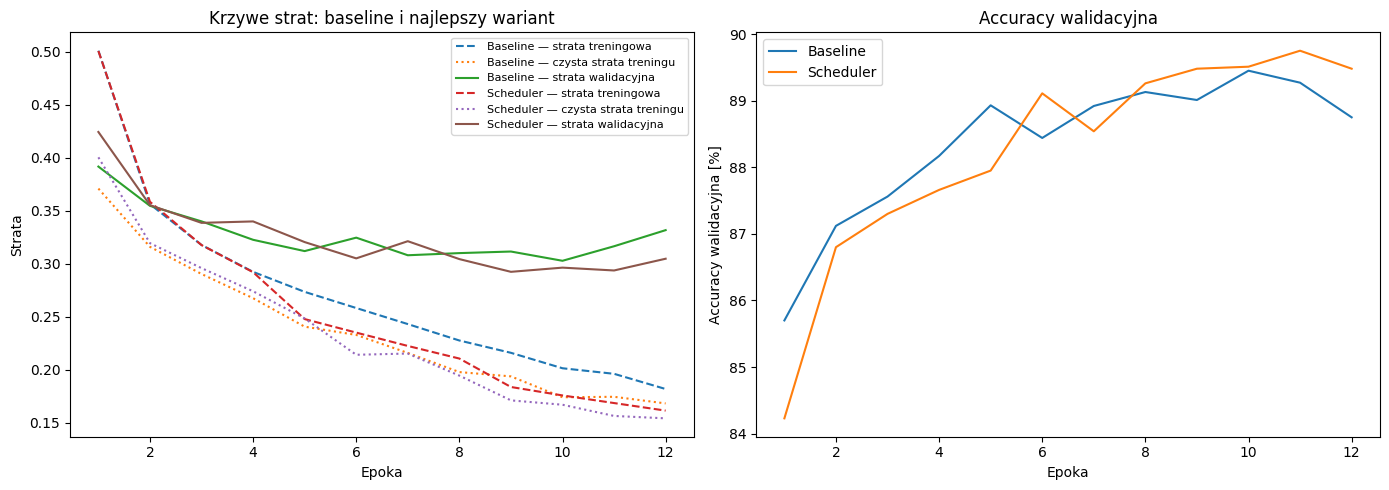

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for r in results:
    h = r["history"]
    epochs = range(1, len(h["train_loss"]) + 1)
    if r["name"] in ("Baseline", best_result["name"]):
        axes[0].plot(epochs, h["train_loss"], "--", label=f'{r["name"]} — strata treningowa')
        axes[0].plot(epochs, h["train_eval_loss"], ":", label=f'{r["name"]} — czysta strata treningu')
        axes[0].plot(epochs, h["val_loss"], "-", label=f'{r["name"]} — strata walidacyjna')
        axes[1].plot(epochs, [x * 100 for x in h["val_acc"]],
                     label=r["name"])

axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Strata")
axes[0].set_title("Krzywe strat: baseline i najlepszy wariant")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Accuracy walidacyjna [%]")
axes[1].set_title("Accuracy walidacyjna")
axes[1].legend()
plt.tight_layout()
plt.show()

## 8. Końcowa ocena na zbiorze testowym

In [8]:
baseline_test_loss, baseline_test_acc = evaluate(baseline_result["model"], test_dl)
best_test_loss, best_test_acc = evaluate(best_result["model"], test_dl)

print(f'Baseline — test accuracy: {baseline_test_acc*100:.2f}% '
      f'| test loss: {baseline_test_loss:.4f}')
print(f'Najlepszy wariant ({best_result["name"]}) — '
      f'test accuracy: {best_test_acc*100:.2f}% | test loss: {best_test_loss:.4f}')

Baseline — test accuracy: 89.19% | test loss: 0.3369
Najlepszy wariant (Scheduler) — test accuracy: 88.98% | test loss: 0.3202


## 9. Luka generalizacji

In [10]:
def report_gap(result):
    i = result["best_epoch"] - 1
    train_eval_loss = result["history"]["train_eval_loss"][i]
    val_loss = result["history"]["val_loss"][i]
    gap = val_loss - train_eval_loss
    print(f'{result["name"]}: epoka={result["best_epoch"]}, '
          f'train_eval_loss={train_eval_loss:.4f}, val_loss={val_loss:.4f}, '
          f'luka={gap:.4f}, val_accuracy={result["best_val_acc"]*100:.2f}%')

report_gap(baseline_result)
report_gap(best_result)

Baseline: epoka=10, train_eval_loss=0.1741, val_loss=0.3028, luka=0.1287, val_accuracy=89.45%
Scheduler: epoka=9, train_eval_loss=0.1712, val_loss=0.2924, luka=0.1212, val_accuracy=89.48%
